# AML - Model Monitoring

Charts of what the pipeline writes every day: data quality of the ingested days, model quality once the labels arrive,
drift of the features and the scores, and the daily alert lists.

Run it from the project folder after `aml_data_pipeline` and `aml_inference_pipeline` have run. It only reads `datamart/`, nothing is written.

In [1]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

%matplotlib inline

monitoring_dir = 'datamart/gold/model_monitoring/'

## 1. Data Quality

In [2]:
dq = pd.concat([pd.read_csv(f) for f in sorted(glob.glob('datamart/silver/data_quality/dq_report_*.csv'))], ignore_index=True)
dq

,snapshot_date,bronze_rows,duplicates_removed,invalid_removed,silver_rows,laundering_rows,currencies
0,2022-09-01,1114921,2,0,1114919,322,15
1,2022-09-02,754449,0,0,754449,408,15
2,2022-09-03,207382,0,0,207382,391,15
3,2022-09-04,207430,0,0,207430,407,15
4,2022-09-05,482650,0,0,482650,471,15
5,2022-09-06,482089,0,0,482089,531,15
6,2022-09-07,482751,1,0,482750,497,15
7,2022-09-08,482773,2,0,482771,539,15
8,2022-09-09,654467,4,0,654463,514,15
9,2022-09-10,208325,0,0,208325,442,15


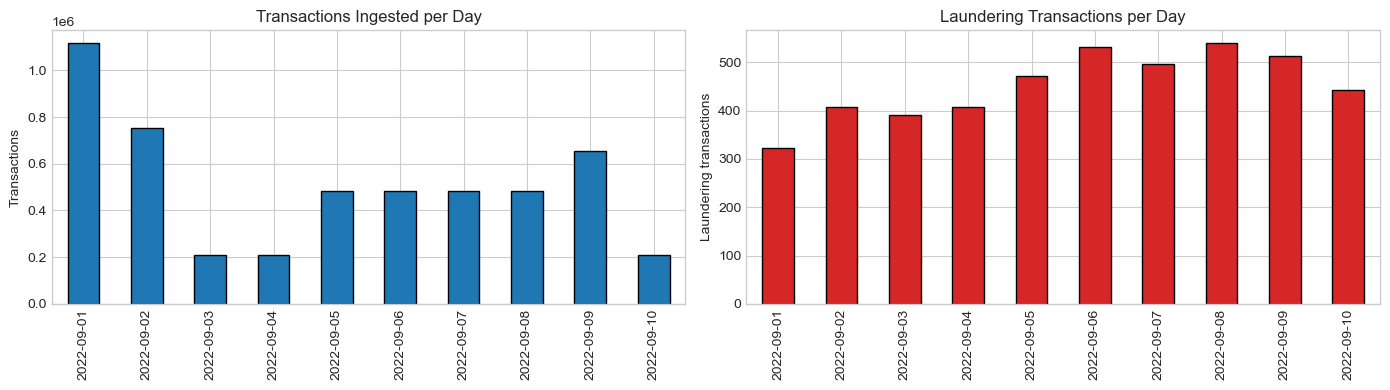

Duplicates removed: 9   Invalid rows removed: 0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

dq.plot(x='snapshot_date', y='silver_rows', kind='bar', ax=axes[0], legend=False, edgecolor='black')
axes[0].set_xlabel('')
axes[0].set_ylabel('Transactions')
axes[0].set_title('Transactions Ingested per Day')

dq.plot(x='snapshot_date', y='laundering_rows', kind='bar', ax=axes[1], legend=False, color='tab:red', edgecolor='black')
axes[1].set_xlabel('')
axes[1].set_ylabel('Laundering transactions')
axes[1].set_title('Laundering Transactions per Day')

plt.tight_layout()
plt.show()

print(f"Duplicates removed: {dq['duplicates_removed'].sum()}   Invalid rows removed: {dq['invalid_removed'].sum()}")

## 2. Model Quality

Labels come 2 days late, so the predictions of snapshot D are scored on day D+2.
The `rule_` rows rank accounts by one feature, what the bank could do without a model.

In [4]:
perf = pd.read_csv(monitoring_dir + 'model_performance.csv', dtype={'model_version': str})

# one name per line on the charts, e.g. "champion v2" (the rules have no version)
perf['model'] = np.where(perf['model_version'] == '-', perf['model_alias'],
                         perf['model_alias'] + ' v' + perf['model_version'])

perf[['snapshot_date', 'model', 'n_accounts', 'n_positive', 'pr_auc', 'p_at_500', 'r_at_2000']].round(4)

,snapshot_date,model,n_accounts,n_positive,pr_auc,p_at_500,r_at_2000
0,2022-09-05,rule_out_cnt,399678,639,0.0272,0.044,0.0454
1,2022-09-05,rule_out_big_cnt,399678,639,0.0248,0.030,0.0329
2,2022-09-06,rule_out_cnt,372229,635,0.0279,0.046,0.0520
3,2022-09-06,rule_out_big_cnt,372229,635,0.0250,0.032,0.0331
4,2022-09-07,rule_out_cnt,252878,565,0.0313,0.042,0.0673
5,2022-09-07,rule_out_big_cnt,252878,565,0.0251,0.030,0.0354
6,2022-09-08,rule_out_cnt,252973,560,0.0304,0.042,0.0714
7,2022-09-08,rule_out_big_cnt,252973,560,0.0265,0.032,0.0339
8,2022-09-09,rule_out_cnt,252987,534,0.0304,0.042,0.0618
9,2022-09-09,rule_out_big_cnt,252987,534,0.0271,0.032,0.0375


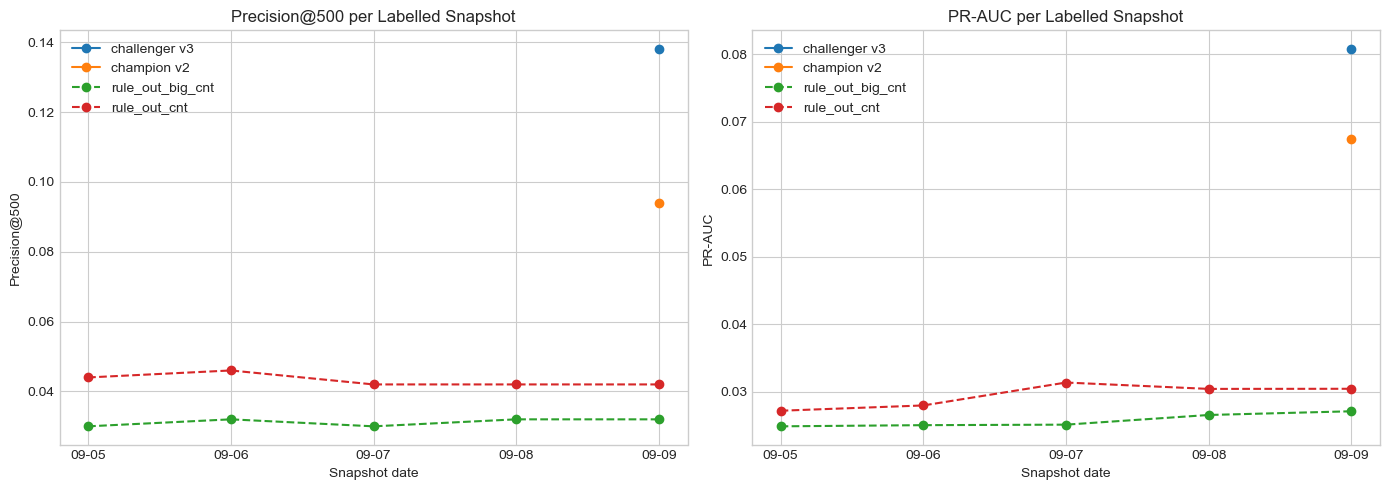

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model, group in perf.groupby('model'):
    style = '--' if model.startswith('rule_') else '-'
    dates = pd.to_datetime(group['snapshot_date'])
    axes[0].plot(dates, group['p_at_500'], style, marker='o', label=model)
    axes[1].plot(dates, group['pr_auc'], style, marker='o', label=model)

axes[0].set_ylabel('Precision@500')
axes[0].set_title('Precision@500 per Labelled Snapshot')
axes[1].set_ylabel('PR-AUC')
axes[1].set_title('PR-AUC per Labelled Snapshot')
for ax in axes:
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
    ax.set_xlabel('Snapshot date')
    ax.legend()

plt.tight_layout()
plt.show()

In [6]:
# what the promotion criteria in the README look at: each candidate next to the champion on the same labelled days
models = perf[~perf['model_alias'].str.startswith('rule_')]
print(models.pivot_table(index='snapshot_date', columns='model', values='p_at_500'))
print()

champion = models[models['model_alias'] == 'champion'].set_index('snapshot_date')['p_at_500']
for model in models.loc[models['model_alias'] != 'champion', 'model'].unique():
    candidate = models[models['model'] == model].set_index('snapshot_date')['p_at_500']
    days = candidate.index.intersection(champion.index)
    wins = (candidate[days] > champion[days]).sum()
    print(f"{model}: {len(days)} labelled day(s), better than the champion on {wins}, "
          f"mean P@500 {candidate[days].mean():.3f} vs {champion[days].mean():.3f}")

print("\nA promotion needs at least 3 labelled days (README, Promotion criteria)")

model          challenger v3  champion v2
snapshot_date                            
2022-09-09             0.138        0.094

challenger v3: 1 labelled day(s), better than the champion on 1, mean P@500 0.138 vs 0.094

A promotion needs at least 3 labelled days (README, Promotion criteria)


## 3. Drift

In [7]:
drift = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(monitoring_dir + 'drift_report_*.csv'))], ignore_index=True)
print(f"Reference snapshot (champion training): {', '.join(drift['reference_snapshot'].unique())}")
pd.crosstab(drift['snapshot_date'], drift['status'])

Reference snapshot (champion training): 2022-09-05


status,drift,ok,watch
snapshot_date,,,
2022-09-09,9,13,3
2022-09-10,4,19,2
2022-09-11,3,22,0


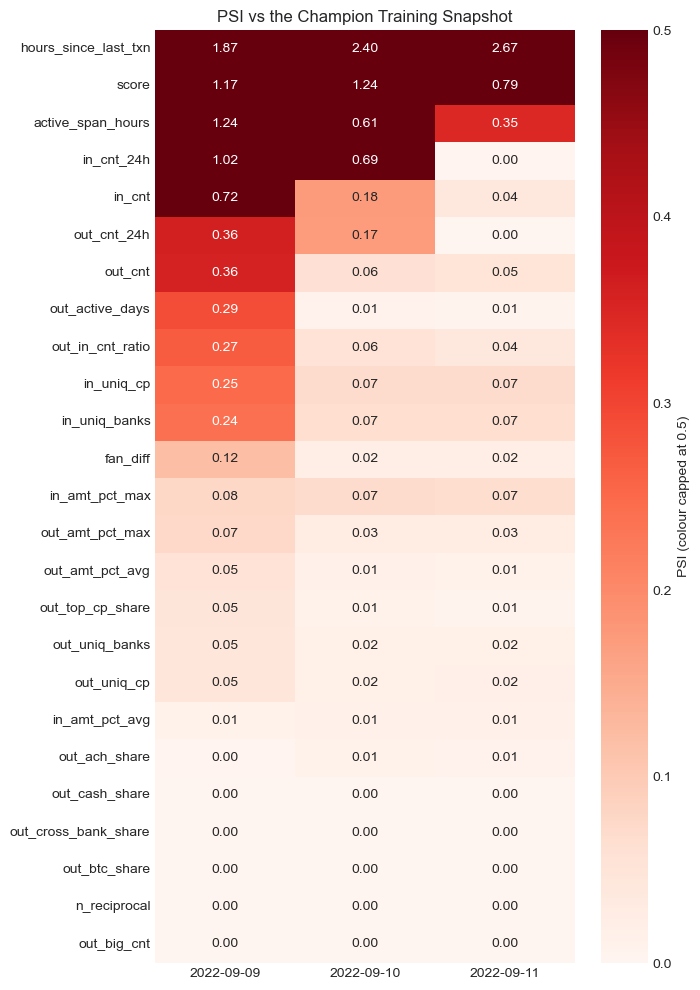

In [8]:
# same thresholds as model_monitor.py: PSI < 0.1 ok, 0.1 - 0.25 watch, > 0.25 drift
psi = drift.pivot(index='feature', columns='snapshot_date', values='psi')
psi = psi.loc[psi.max(axis=1).sort_values(ascending=False).index]

plt.figure(figsize=(7, 10))
sns.heatmap(psi, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=0.5, cbar_kws={'label': 'PSI (colour capped at 0.5)'})
plt.xlabel('')
plt.ylabel('')
plt.title('PSI vs the Champion Training Snapshot')
plt.tight_layout()
plt.show()

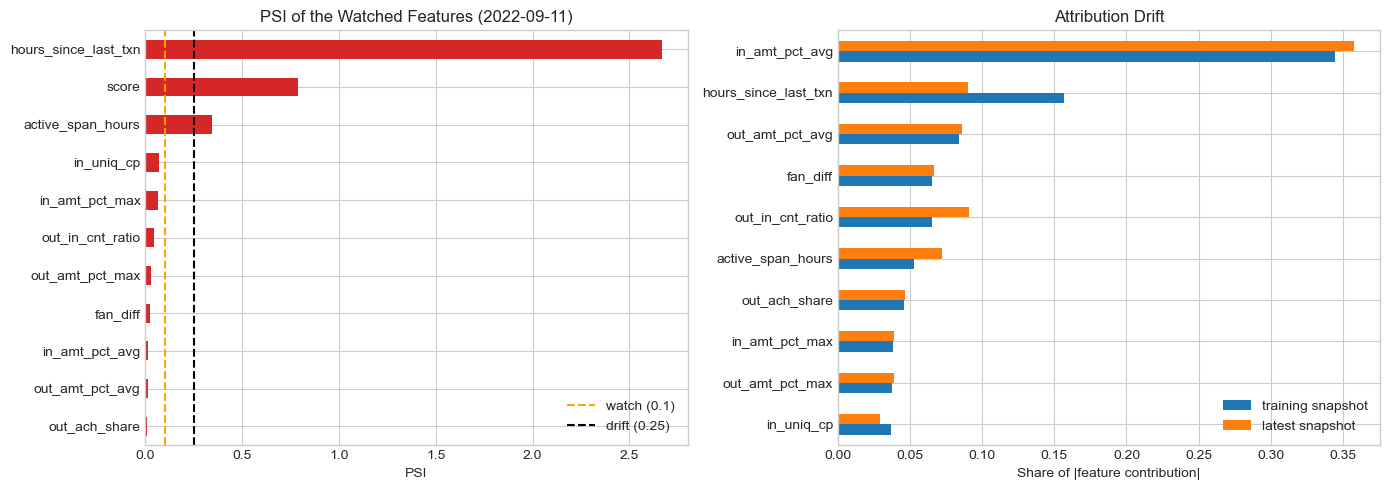

In [9]:
# the monitor only alerts on the 10 features the champion relies on most, plus the score
latest = drift[drift['snapshot_date'] == drift['snapshot_date'].max()]
watched = latest.dropna(subset=['ref_attribution_share']).nlargest(10, 'ref_attribution_share')
watched = pd.concat([watched, latest[latest['feature'] == 'score']]).set_index('feature')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

watched['psi'].sort_values().plot(kind='barh', ax=axes[0], color='tab:red', label='_nolegend_')
axes[0].axvline(0.1, color='orange', linestyle='--', label='watch (0.1)')
axes[0].axvline(0.25, color='black', linestyle='--', label='drift (0.25)')
axes[0].set_xlabel('PSI')
axes[0].set_ylabel('')
axes[0].set_title(f"PSI of the Watched Features ({latest['snapshot_date'].iloc[0]})")
axes[0].legend()

# share of the champion's |feature contribution|: does the model lean on other features now?
share = watched.drop('score')[['ref_attribution_share', 'cur_attribution_share']].sort_values('ref_attribution_share')
share.columns = ['training snapshot', 'latest snapshot']
share.plot(kind='barh', ax=axes[1])
axes[1].set_xlabel('Share of |feature contribution|')
axes[1].set_ylabel('')
axes[1].set_title('Attribution Drift')

plt.tight_layout()
plt.show()

In [10]:
alerts = pd.read_csv(monitoring_dir + 'drift_alerts.csv')
alerts

,snapshot_date,champion_version,shadow_models,drifted
0,2022-09-09,2,challenger v3,"hours_since_last_txn, out_in_cnt_ratio, active_span_hours, score"
1,2022-09-10,2,challenger v3,"hours_since_last_txn, active_span_hours, score"
2,2022-09-11,2,challenger v3,"hours_since_last_txn, active_span_hours, score"


## 4. Champion and Shadow Scores

In [11]:
preds = pd.concat([pd.read_parquet(f) for f in sorted(glob.glob('datamart/gold/model_predictions/*/*.parquet'))],
                  ignore_index=True)
preds.groupby(['snapshot_date', 'model_alias', 'model_version'])['score'].describe().round(4)

count    mean     std     min  \
snapshot_date model_alias model_version                                     
2022-09-09    challenger  3              252987.0  0.0021  0.0047  0.0004   
              champion    2              252987.0  0.0020  0.0023  0.0005   
2022-09-10    challenger  3              366476.0  0.0033  0.0070  0.0004   
              champion    2              366476.0  0.0022  0.0042  0.0005   
2022-09-11    challenger  3              367544.0  0.0019  0.0058  0.0004   
              champion    2              367544.0  0.0017  0.0039  0.0005   

                                            25%     50%     75%     max  
snapshot_date model_alias model_version                                  
2022-09-09    challenger  3              0.0015  0.0018  0.0020  0.7553  
              champion    2              0.0017  0.0018  0.0021  0.4467  
2022-09-10    challenger  3              0.0016  0.0018  0.0026  0.8020  
              champion    2              0.0013  0.0018  0.0023  0.6430  
2022-09-11    challenger  3              0.0011  0.0016  0.0020  0.8020  
              champion    2              0.0012  0.0018  0.0020  0.6427

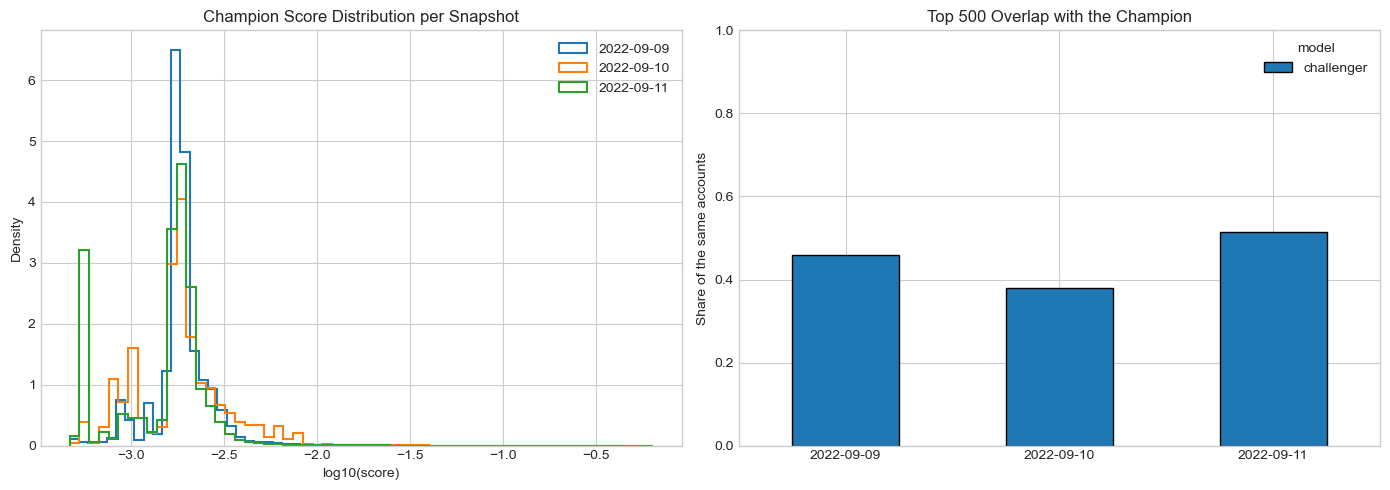

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

champ = preds[preds['model_alias'] == 'champion']
for day, group in champ.groupby('snapshot_date'):
    axes[0].hist(np.log10(group['score'].clip(lower=1e-6)), bins=60, density=True, histtype='step', linewidth=1.5, label=day)
axes[0].set_xlabel('log10(score)')
axes[0].set_ylabel('Density')
axes[0].set_title('Champion Score Distribution per Snapshot')
axes[0].legend()

# how much do the champion and the shadow models agree on who goes into the top 500?
rows = []
for (day, alias), group in preds[preds['model_alias'] != 'champion'].groupby(['snapshot_date', 'model_alias']):
    top_shadow = set(group.nlargest(500, 'score')['acct'])
    top_champion = set(champ[champ['snapshot_date'] == day].nlargest(500, 'score')['acct'])
    rows.append({'snapshot_date': day, 'model': alias, 'overlap': len(top_shadow & top_champion) / 500})

overlap = pd.DataFrame(rows).pivot(index='snapshot_date', columns='model', values='overlap')
overlap.plot(kind='bar', ax=axes[1], edgecolor='black', rot=0)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel('')
axes[1].set_ylabel('Share of the same accounts')
axes[1].set_title('Top 500 Overlap with the Champion')

plt.tight_layout()
plt.show()

## 5. Alert Lists

In [13]:
alert_lists = pd.concat([pd.read_csv(f) for f in sorted(glob.glob('datamart/gold/alert_list/alert_list_*.csv'))],
                        ignore_index=True)
alert_lists.groupby('snapshot_date').agg(alerts=('acct', 'size'),
                                         model_version=('model_version', 'first'),
                                         top_score=('score', 'max'),
                                         score_of_last=('score', 'min'))

,alerts,model_version,top_score,score_of_last
snapshot_date,,,,
2022-09-09,500,2,0.446701,0.016025
2022-09-10,500,2,0.642956,0.018322
2022-09-11,500,2,0.642748,0.012320


In [14]:
days = sorted(alert_lists['snapshot_date'].unique())
for prev, day in zip(days, days[1:]):
    prev_accts = set(alert_lists.loc[alert_lists['snapshot_date'] == prev, 'acct'])
    accts = set(alert_lists.loc[alert_lists['snapshot_date'] == day, 'acct'])
    print(f"{day}: {len(accts & prev_accts)} of {len(accts)} accounts were already on the list of {prev}")

2022-09-10: 332 of 500 accounts were already on the list of 2022-09-09
2022-09-11: 270 of 500 accounts were already on the list of 2022-09-10


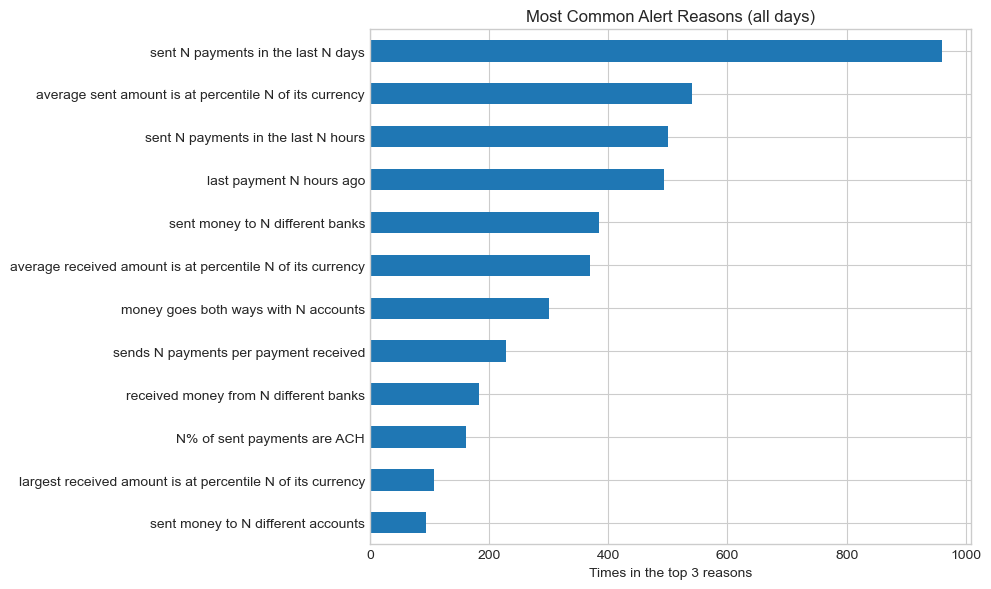

In [15]:
# the reasons contain numbers ("received money from 8 different banks"), replace them to count the kind of reason
reasons = pd.concat([alert_lists[c] for c in ['reason_1', 'reason_2', 'reason_3']]).dropna()
reasons = reasons.str.replace(r'\d+(\.\d+)?', 'N', regex=True)
reasons = reasons.str.replace(r'N (hour|account|payment)\b', r'N \1s', regex=True)   # "1 hour" -> "N hours"

plt.figure(figsize=(10, 6))
reasons.value_counts().head(12).sort_values().plot(kind='barh')
plt.xlabel('Times in the top 3 reasons')
plt.title('Most Common Alert Reasons (all days)')
plt.tight_layout()
plt.show()

## 6. Monitoring Summary

The numbers below are from the replay of Sep 1-10 with the first models (champion v2, challenger v3). They change when the DAGs run again.

### Data Quality:
- 10 days ingested (Sep 1-10), 207k to 1.1M transactions a day, 15 currencies every day
- 9 duplicate rows removed in total, no invalid rows

### Model Quality:
- Only snapshot 2022-09-09 has both labels and model scores so far (the replay ends there)
- Challenger v3 (with graph features): P@500 0.138, PR-AUC 0.081. Champion v2: P@500 0.094, PR-AUC 0.067
- Both are 2-3x better than the best rule (`out_cnt`, P@500 0.042)
- 1 labelled day is not enough for a promotion, the criteria ask for at least 3

### Drift:
- A drift alert on all 3 scored snapshots (09-09, 09-10, 09-11), always on `hours_since_last_txn`, `active_span_hours` and the score (PSI 0.35 - 2.67)
- On 09-09 many count features drift too, by 09-11 all other features are back below 0.1
- The drifting features are about timing; the champion's training window (Sep 1-4) includes the quiet weekend, which is the likely cause
- Attribution: the share of `hours_since_last_txn` fell from 0.16 to 0.09, `in_amt_pct_avg` stays the main feature (about 0.35)

### Shadow Comparison and Alert Lists:
- Champion and challenger share only 38% - 51% of their top 500 accounts, so a promotion would change a lot of the daily list
- 332 of 500 accounts on 09-10 and 270 of 500 on 09-11 were already on the list of the day before
- Most common reasons: payments sent in the last 4 days, average sent amount percentile, payments in the last 24 hours, time since the last payment